# What France reimburses: medicines dispensed in pharmacies, 2019–2025
Data: Open Medic (Assurance Maladie, extracted from the national health data system SNDS) — every box of medicine dispensed by a retail pharmacy and reimbursed, by molecule, age group, sex and region. Population: INSEE. Tables come from SQL queries on `data/medicines.duckdb` (see `sql/`), charts from `src/analysis.py`.

In [1]:
import sys; sys.path.insert(0, '../src')
from IPython.display import Image
import pandas as pd; pd.set_option('display.precision', 3); pd.set_option('display.width', 160)
from analysis import *

## 0. Checks
The files exist at three levels of detail (molecule, class, group). Summing spending at each level must give the same total: it does, to the euro.

In [2]:
consistency()

,year,from_atc5_bn,from_atc4_bn,from_atc2_bn
0,2019,19.144,19.144,19.144
1,2020,19.245,19.245,19.245
2,2021,20.747,20.747,20.747
3,2022,22.682,22.682,22.682
4,2023,24.440,24.440,24.440
5,2024,26.038,26.038,26.038
6,2025,27.442,27.442,27.442


In [3]:
data_quality()

,issue,share
0,age group unknown,8.912e-04
1,sex unknown,1.406e-03
2,region not a metropolitan region,6.419e-02
3,molecule label missing,9.359e-04
4,molecule appears under 2+ ATC codes,1.907e-01


19% of spending concerns molecules that appear under two or more ATC codes: the WHO reclassified GLP-1 analogues in 2020 and many cancer drugs in 2021, and some labels are misspelt in some years. `build_db.py` links codes and labels into stable molecules (union-find) so that growth is not mistaken for a new drug.

## 1. Spending grows, volume does not

In [4]:
t = totals(); t

,year,reimbursed_bn,boxes_bn,base_per_box
0,2019,19.144,2.311,9.768
1,2020,19.245,2.238,9.991
2,2021,20.747,2.282,10.501
3,2022,22.682,2.368,11.017
4,2023,24.440,2.346,11.921
5,2024,26.038,2.368,12.554
6,2025,27.442,2.327,13.512


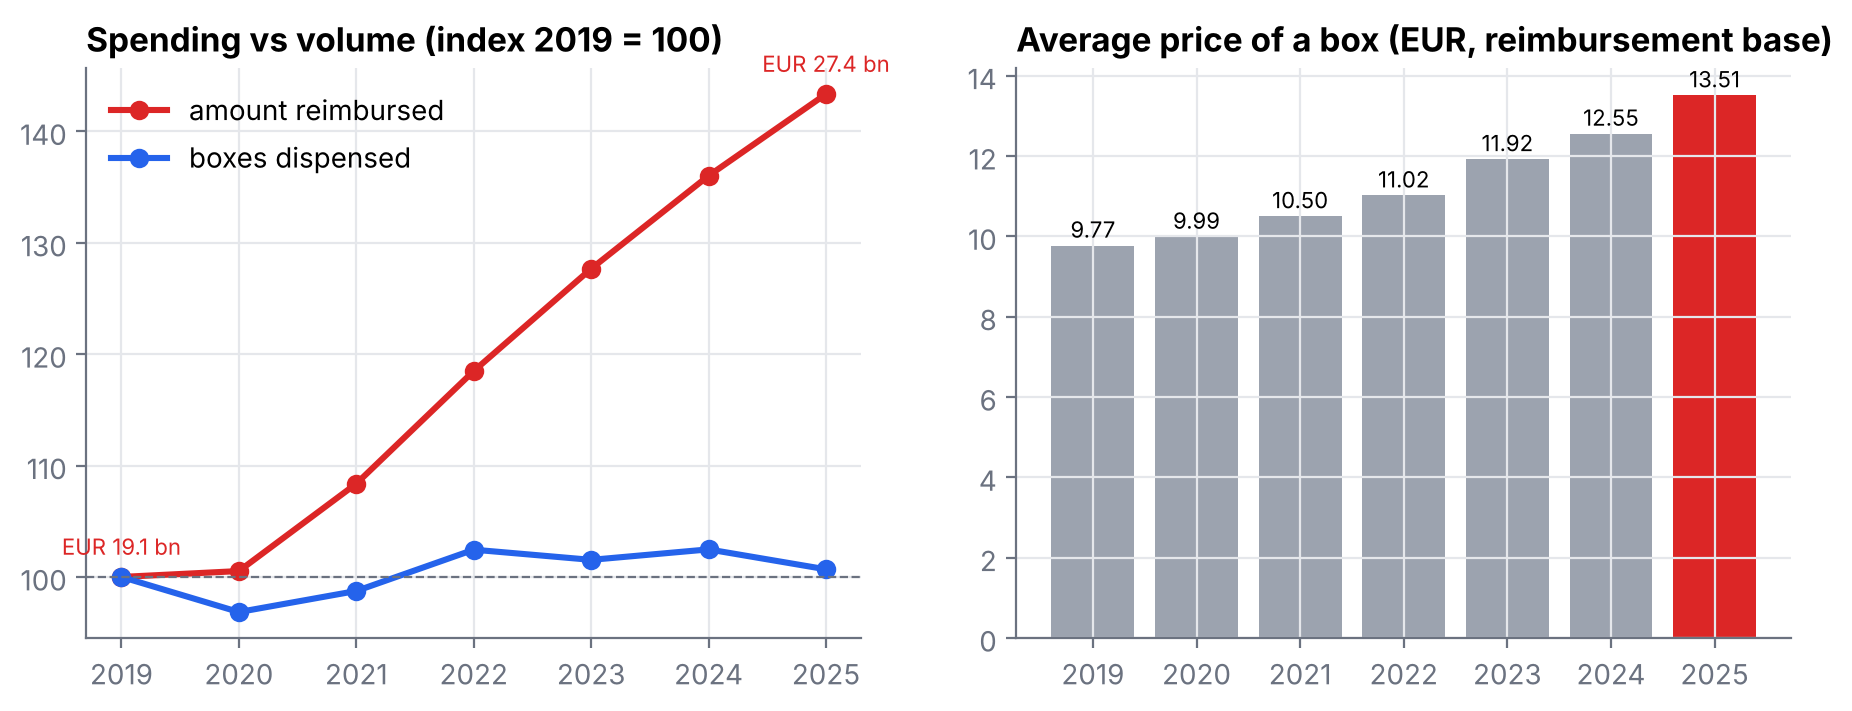

In [5]:
fig_totals(t); Image('../figures/01_spending_vs_volume.png')

Reimbursements rose by 43% in six years while the number of boxes stayed flat: the growth comes from the price and the mix of medicines, not from people taking more.

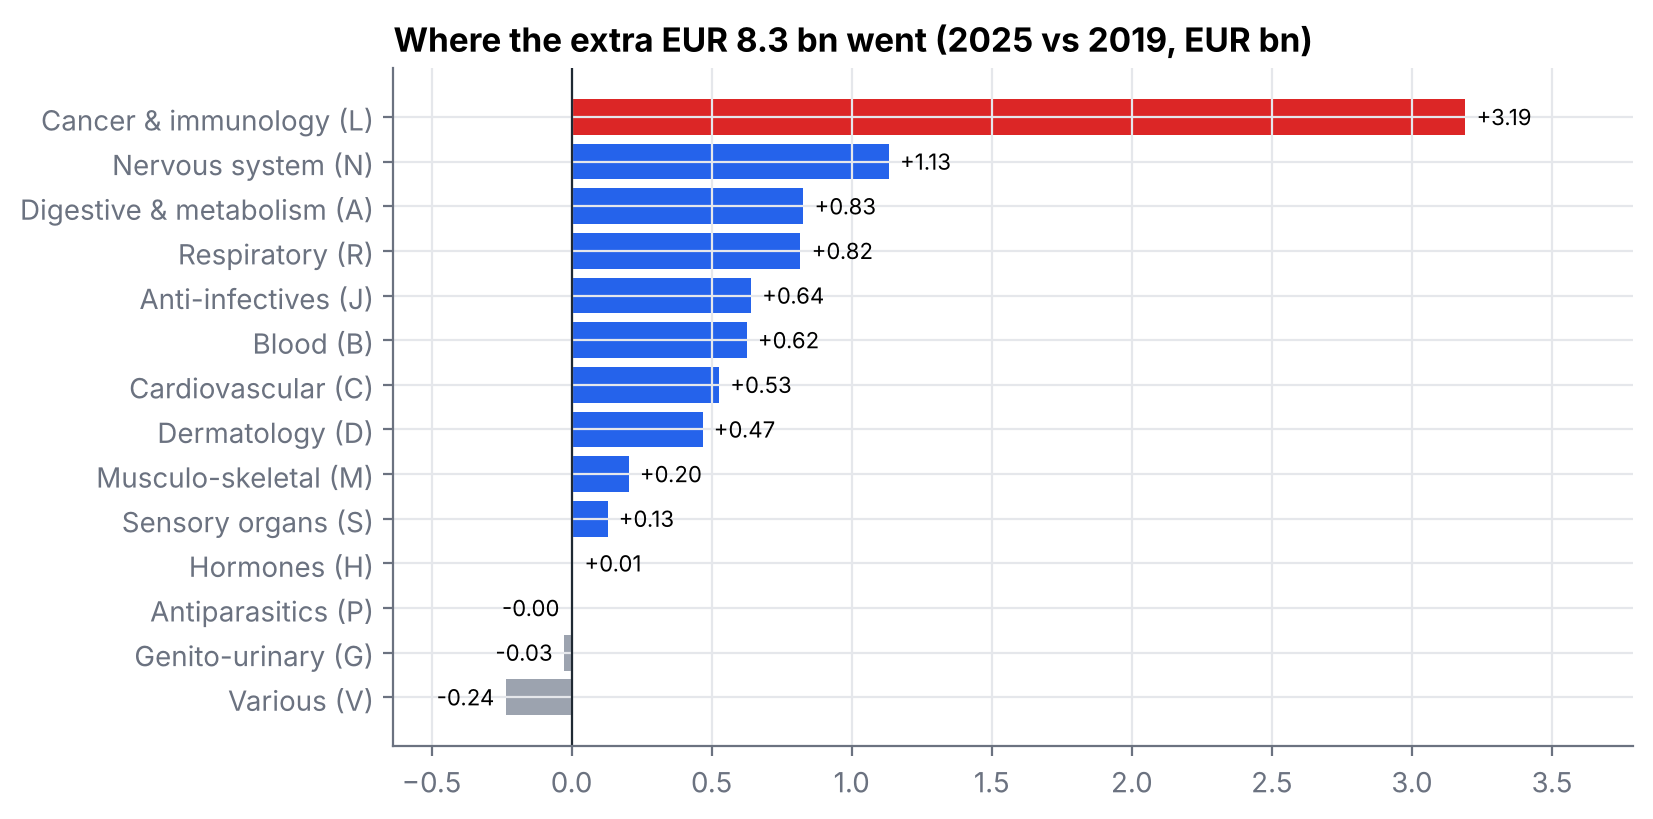

In [6]:
g = growth_by_group(); fig_growth_by_group(g); Image('../figures/02_growth_by_group.png')

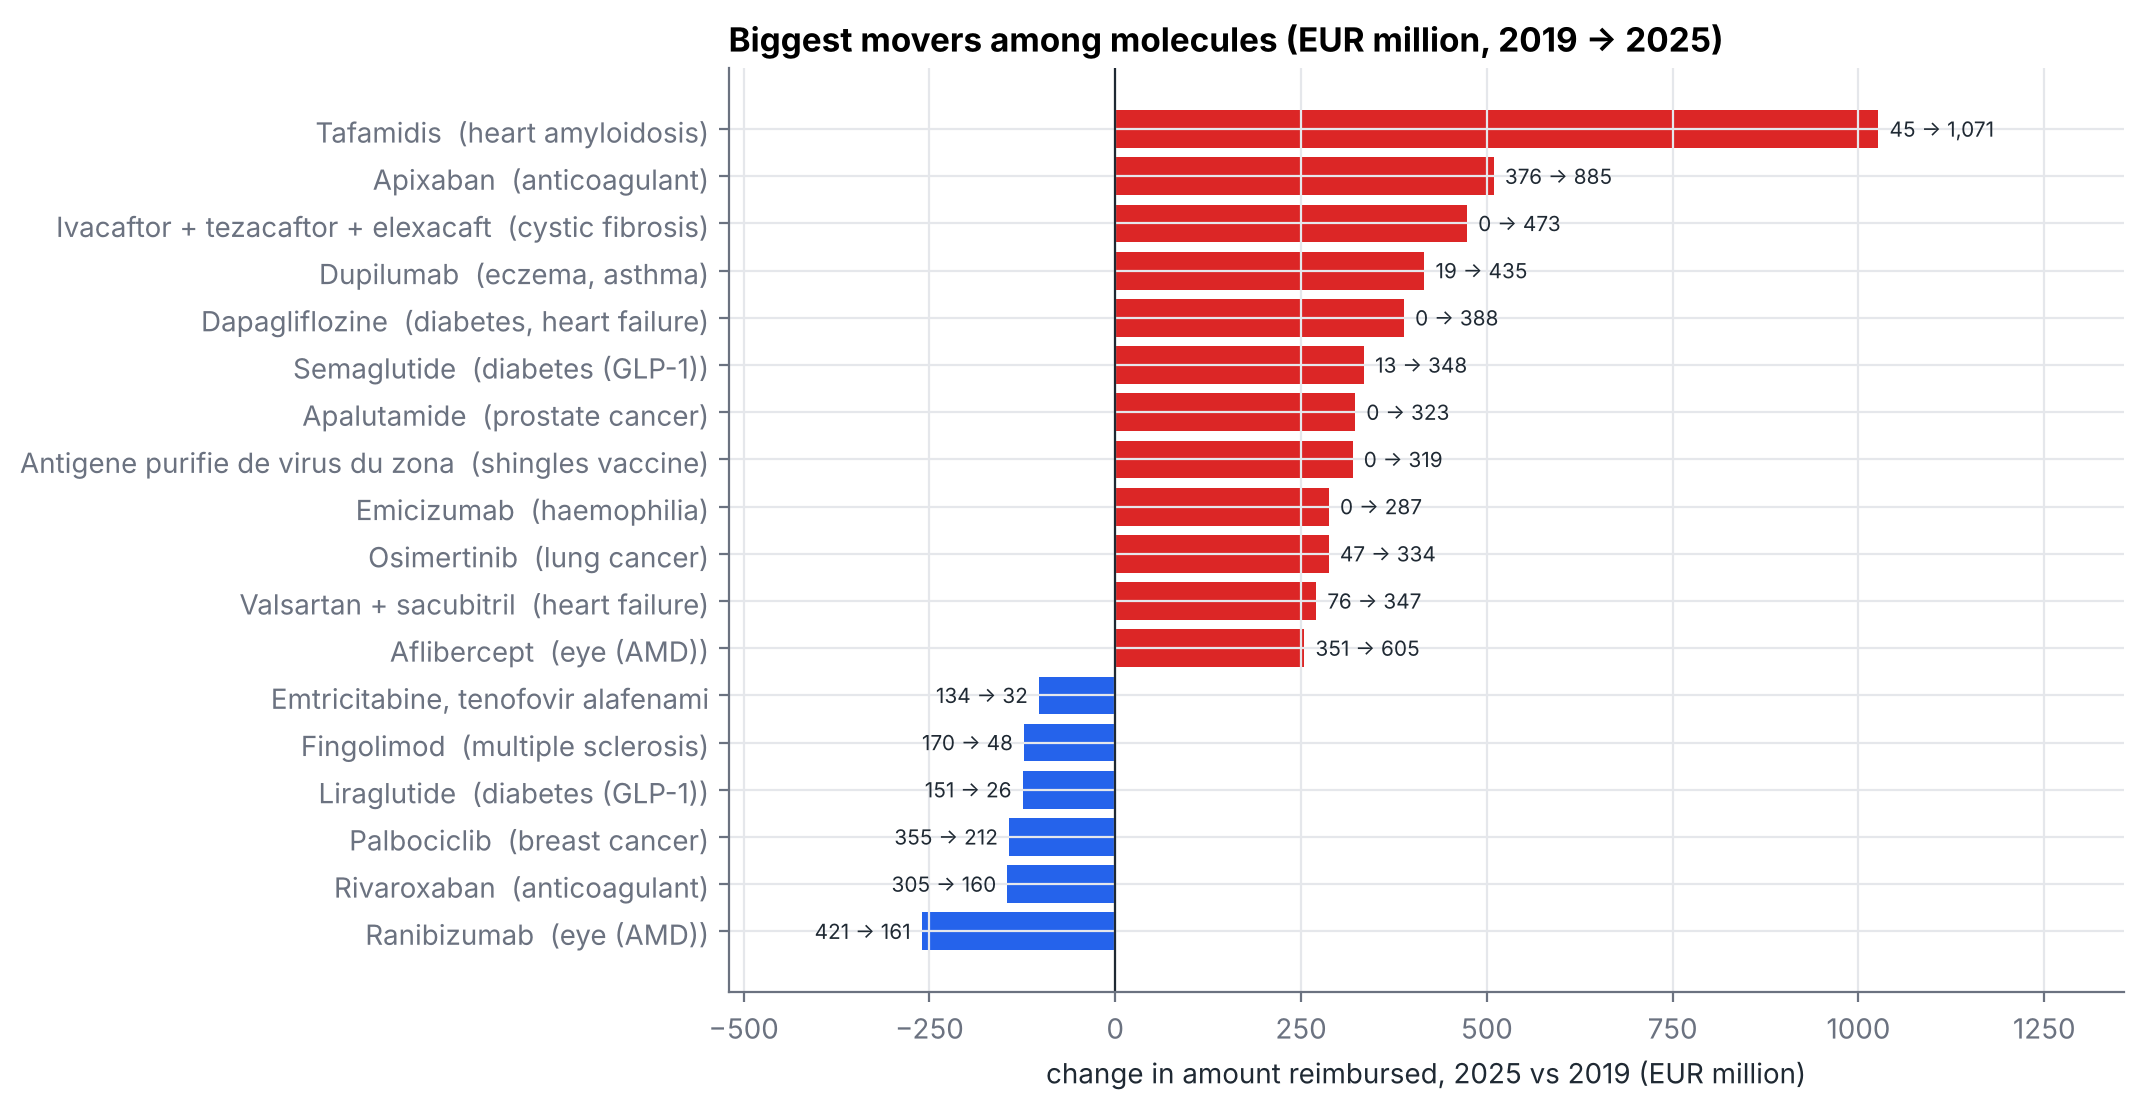

In [7]:
m = molecule_movers(); fig_movers(m); Image('../figures/03_molecule_movers.png')

In [8]:
concentration()

,year,molecules,top10_share,top50_share,molecules_for_half
0,2019,1047,0.173,0.427,70
1,2020,1060,0.183,0.445,65
2,2021,1070,0.185,0.446,64
3,2022,1069,0.189,0.461,60
4,2023,1085,0.191,0.472,58
5,2024,1097,0.189,0.474,57
6,2025,1097,0.199,0.479,55


Spending is concentrating: in 2025, 55 molecules out of about 1,100 make up half of all reimbursements (70 in 2019). Tafamidis, a treatment for a heart disease (transthyretin amyloidosis), went from 45 to 1,071 million euros and is now the most reimbursed molecule, for about 16,000 patients.

## 2. Three stories

In [9]:
glp1()

,year,patients_k,reimbursed_m,share_60_plus,share_women
0,2020,415.264,352.441,0.627,0.462
1,2021,513.514,413.916,0.633,0.459
2,2022,629.035,500.119,0.638,0.459
3,2023,755.798,589.060,0.639,0.461
4,2024,783.106,582.112,0.644,0.464
5,2025,931.551,674.562,0.637,0.468


In [10]:
antibiotics().pivot(index='year', columns='age_group', values='patients_m')

age_group,0,20,60
year,,,
2019,6.653,13.620,7.761
2020,5.006,11.520,6.615
2021,5.422,11.891,6.669
2022,6.474,13.211,7.676
2023,6.188,13.020,7.744
2024,6.424,13.477,8.173
2025,5.582,12.561,7.917


In [11]:
adhd().pivot(index='year', columns='age_group', values='patients_k')

age_group,0,20,60
year,,,
2019,79.364,16.674,0.948
2020,81.553,18.259,1.141
2021,92.716,23.924,1.254
2022,107.383,35.140,1.491
2023,124.027,52.439,1.825
2024,148.932,77.797,2.464
2025,184.682,113.833,3.301


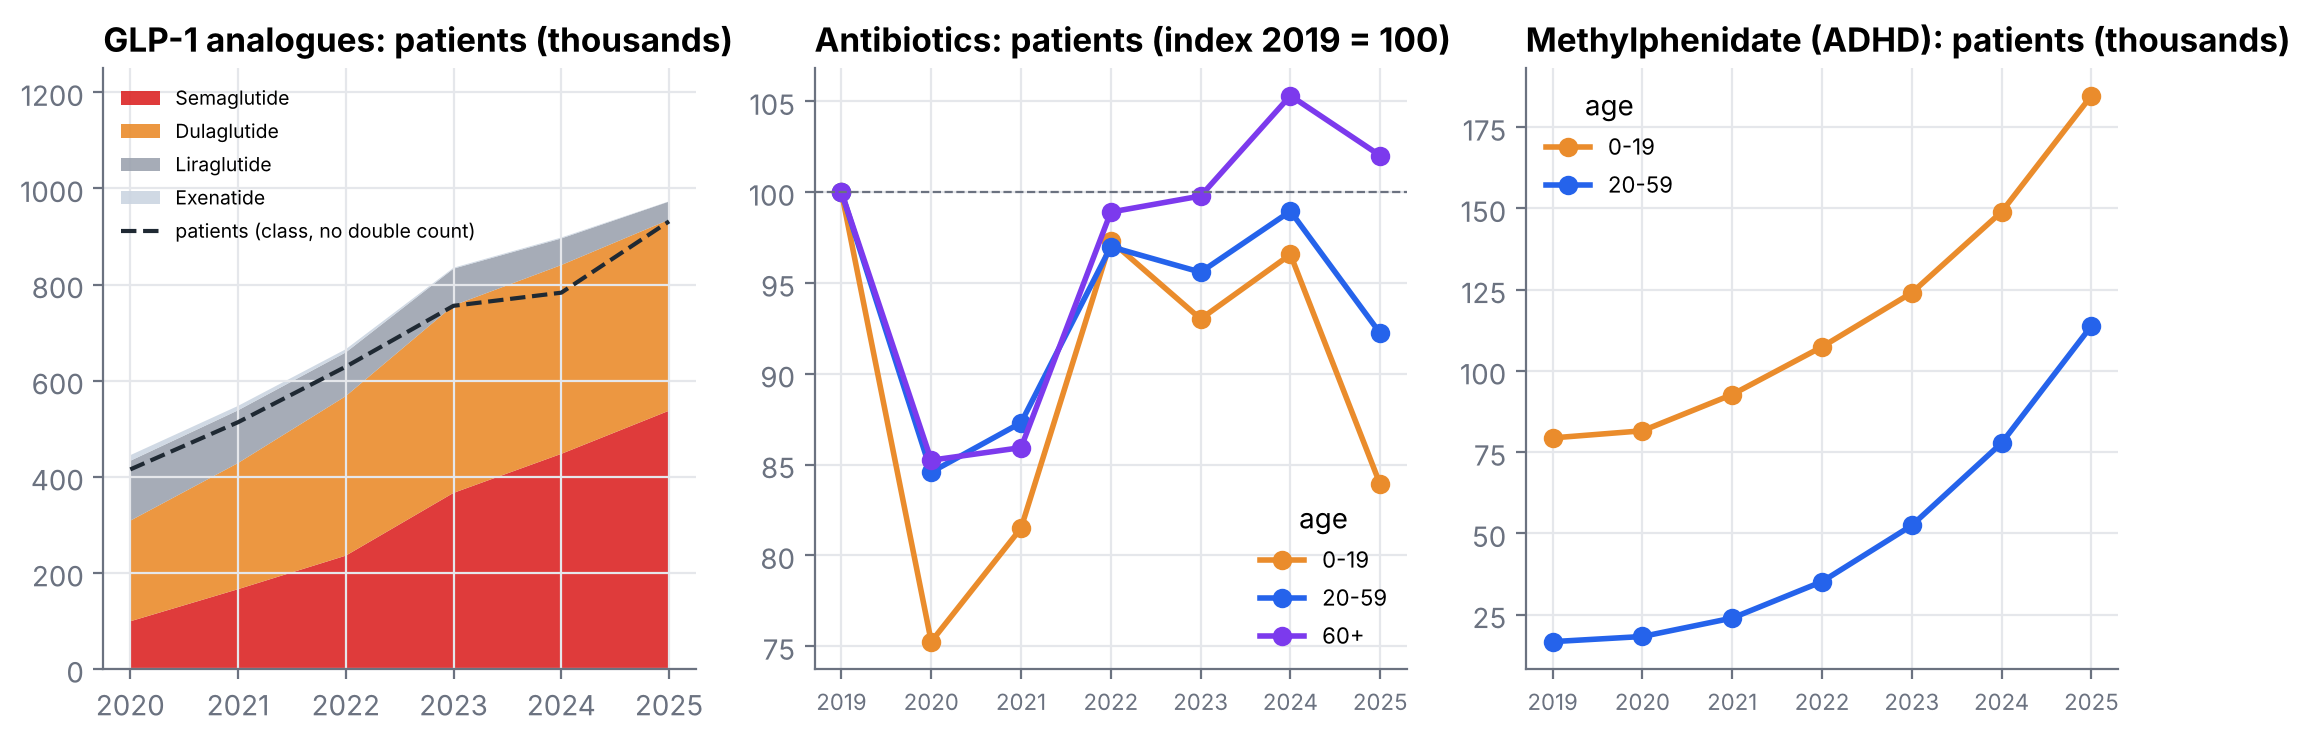

In [12]:
fig_stories(glp1(), glp1_molecules(), antibiotics(), adhd()); Image('../figures/04_three_stories.png')

* **GLP-1 analogues** (diabetes): patients more than doubled, from 415,000 in 2020 to 932,000 in 2025, led by semaglutide.
* **Antibiotics**: lockdowns and masks cut the number of patients by 17% in 2020 (25% for under-20s); it was back to its 2019 level in 2024.
* **Methylphenidate** (ADHD): adult patients went from 17,000 to 114,000, children from 79,000 to 185,000.

## 3. Regions: compare like with like
Older regions spend more simply because their population is older. Direct age standardisation removes that effect.

In [13]:
age_profile()

,age_group,per_inhabitant,population_m
0,0,109.661,15.249
1,20,262.074,32.136
2,60,852.033,18.099


In [14]:
r = regions(); r

,region,region_name,crude_per_inhabitant,standardised_per_inhabitant,share_60_plus
0,93,Provence-Alpes-Côte d'Azur,458.533,436.517,0.307
1,32,Hauts-de-France,404.369,419.632,0.256
2,11,Île-de-France,357.511,398.607,0.213
3,44,Grand Est,400.916,395.370,0.283
4,76,Occitanie,408.477,391.071,0.302
5,28,Normandie,397.278,386.274,0.296
6,75,Nouvelle-Aquitaine,411.851,383.497,0.319
7,27,Bourgogne-Franche-Comté,394.050,371.476,0.311
8,84,Auvergne-Rhône-Alpes,366.427,371.401,0.269
9,24,Centre-Val-de-Loire,379.744,364.406,0.303


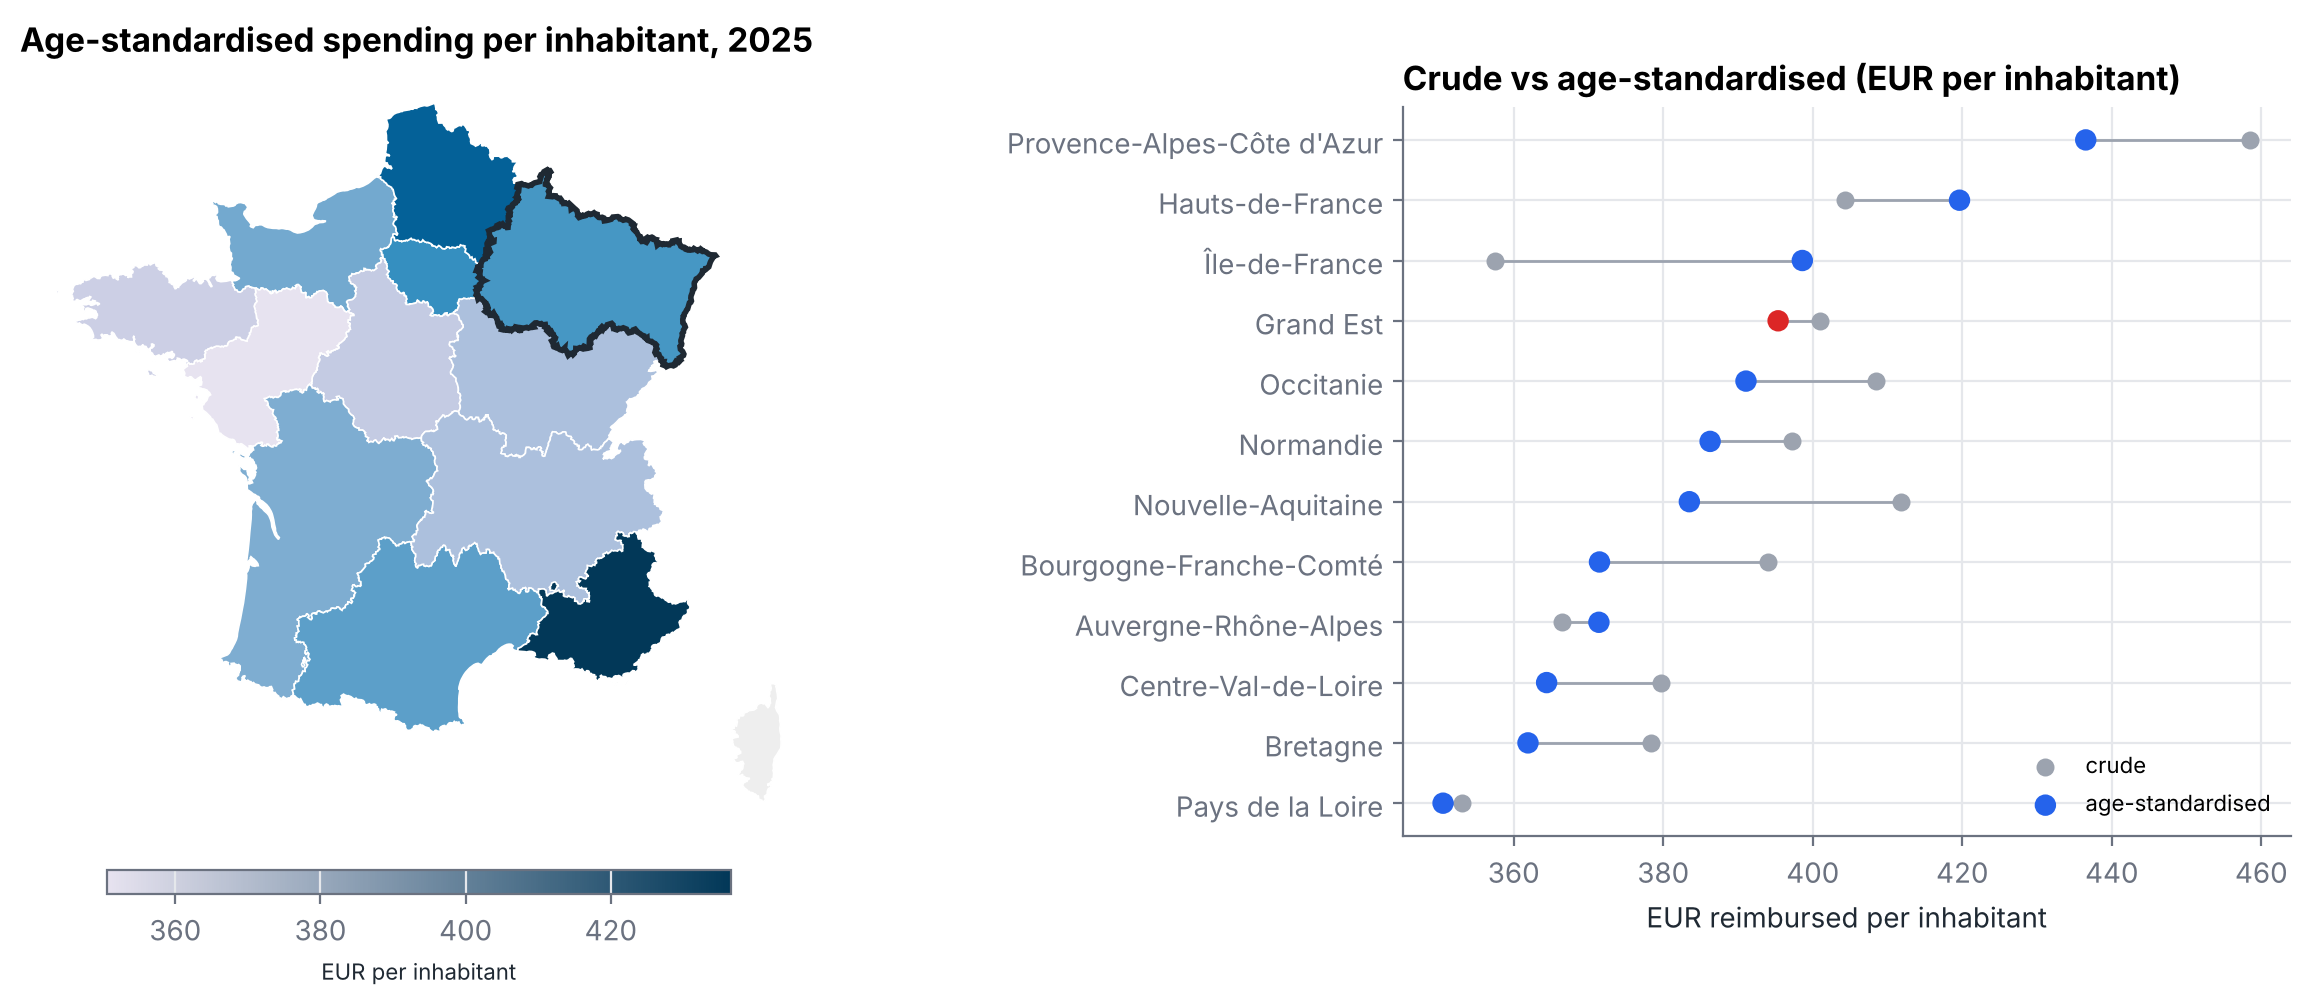

In [15]:
fig_regions(r); Image('../figures/05_regions.png')

Île-de-France looks cheap only because it is young: once standardised it moves from 11th to 3rd. Grand Est is 5th of 12 before standardisation and 4th after, slightly above the median.